# Barometric boiling-point formulas vs. measured records

**Question.** How well does a simple barometric formula predict the boiling point of water at different altitudes, compared with published measurements?

**What this notebook does.** It runs the artifact's `method.py`, split into cells. Two barometric formulas give the air pressure at an elevation: an isothermal one and a lapse-rate one. Each pressure is converted to a boiling temperature by inverting the explicit Wagner-Pruss (IAPWS-95) saturation equation by bisection. The results are then tested against measured station-pressure and boiling-temperature records.

**Data.** `mini_demo_data.json` holds the artifact's accepted-records list, which is an empty list (`[]`). No verified measured records with elevation, station pressure, boiling temperature and stated uncertainty were found. The measurement test is therefore UNDERPOWERED and no claim is decided.

**What you will see.** The notebook prints the saturation checks, the model-only structural term on a 0-4000 m grid (isothermal minus lapse-rate boiling temperature), the claim verdicts, and a plot of the structural term. **These model-only numbers are not validation against measurements.**

## Install dependencies

Packages that Colab does not pre-install are always installed. Core packages that Colab does pre-install are installed only outside Colab, at Colab's exact versions, so the Colab runtime is never modified.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Not pre-installed on Colab: always install
_pip('loguru==0.8.0')
_pip('--no-deps', 'iapws==1.5.5')

# Pre-installed on Colab: install locally only, at Colab's exact versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0', 'scipy==1.16.3')


## Imports and figure style

The imports are the original script's import block. The notebook adds matplotlib and the shared figure style.

In [2]:
import csv
import hashlib
import json
import math
import sys
from pathlib import Path

import numpy as np
from loguru import logger
import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})


## Load the data

The records are read from the GitHub raw URL. If the URL is unavailable, the local `mini_demo_data.json` is used.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-afc680-barometric-formula-predicts-waters/main/round-2/experiment-3/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")


In [4]:
data = load_data()
print(f"Loaded {len(data)} measured records (this artifact has 0 verified records)")


GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Loaded 0 measured records (this artifact has 0 verified records)


## Config

All tunable parameters are set here. The values start at the smallest that run. The comment on each line gives the original value.

In [5]:
ELEV_MAX_M = 4000.0  # top of the model-only grid, 0-4000 m (original 4000.0)
N_BOOT = 10000  # bootstrap resamples (original 10000); only used when measured sites exist
BOOT_SEED = 20260314  # fixed seed for the bootstrap (original 20260314)
MIN_SITES = 15  # minimum accepted sites before a test is decided (original 15)


## Constants of the standard atmosphere and of Wagner-Pruss

The standard atmosphere (US 1976) sets the isothermal and lapse-rate pressure profiles. The Wagner-Pruss 2002 coefficients give the saturation vapour pressure of water. The notebook's `WORKSPACE` points at the current directory, because `__file__` is not defined in a notebook.

In [6]:
WORKSPACE = Path.cwd()  # notebook fix: __file__ is not defined in a notebook
DATA_DIR = WORKSPACE / "data"
RESULTS_DIR = WORKSPACE / "results"
LOGS_DIR = WORKSPACE / "logs"

HOLDOUT_EVERY = 3  # every third site after sorting by elevation
RMS_CLAIM_A_K = 0.3
DISCONFIRM_K = 0.5
TOTAL_BOUND_K = 0.6
DTB_DP_K_PER_KPA = 0.28  # near 1 atm, checked numerically below
TARGET_ALL_SITES = 25

# --- standard atmosphere (US 1976) and barometric formulas -------------------
R_GAS = 8.314462618  # J/(mol K)
M_AIR = 0.0289644  # kg/mol
G0 = 9.80665  # m/s^2
T0 = 288.15  # K
P0 = 101325.0  # Pa
LAPSE = 0.0065  # K/m
H_ISO = R_GAS * T0 / (M_AIR * G0)  # ~8434.5 m
EXP_LAPSE = G0 * M_AIR / (R_GAS * LAPSE)  # ~5.2559
Z_TROPO_MAX = 11000.0

# --- Wagner-Pruss 2002 (IAPWS-95 companion), saturation pressure ------------
# Source: W. Wagner and A. Pruss, J. Phys. Chem. Ref. Data 31, 387-535 (2002),
# Table 2 (psat equation). Coefficients copied as published.
TC = 647.096
PC = 22064000.0
WP_A = (-7.85951783, 1.84408259, -11.7866497, 22.6807411, -15.9618719, 1.80122502)
WP_EXP = (1.0, 1.5, 3.0, 3.5, 4.0, 7.5)
T_TRIPLE = 273.16
T_NBP = 373.124
T_CRIT = TC


## Saturation pressure, its inversion, and the two barometric formulas

`invert_tb` finds the boiling temperature at a given pressure by bisection on `psat_wp`. `p_isothermal` and `p_lapse` give the pressure at an elevation under each formula.

In [7]:
def psat_wp(t_k: float) -> float:
    """Saturation vapour pressure (Pa) from the explicit Wagner-Pruss equation."""
    tau = 1.0 - t_k / TC
    s = sum(a * tau**e for a, e in zip(WP_A, WP_EXP))
    return PC * math.exp((TC / t_k) * s)


def invert_tb(p_pa: float, tol: float = 1e-9, max_iter: int = 200) -> float:
    """Boiling temperature (K) at pressure p by bisection on psat_wp."""
    lo, hi = T_TRIPLE, 378.15
    if not (psat_wp(lo) <= p_pa <= psat_wp(hi)):
        raise ValueError(f"pressure {p_pa:.1f} Pa outside saturation range")
    for _ in range(max_iter):
        mid = 0.5 * (lo + hi)
        if psat_wp(mid) < p_pa:
            lo = mid
        else:
            hi = mid
        if hi - lo < tol:
            return 0.5 * (lo + hi)
    raise RuntimeError("bisection did not converge")


def p_isothermal(z_m: float) -> float:
    return P0 * math.exp(-z_m / H_ISO)


def p_lapse(z_m: float) -> float:
    if z_m > Z_TROPO_MAX:
        raise ValueError("lapse-rate formula used above tropopause")
    return P0 * (1.0 - LAPSE * z_m / T0) ** EXP_LAPSE


## Checks: normal boiling point, triple point, round trip, and an iapws cross-check

The explicit equation must reproduce the normal boiling point (101325 Pa at 373.124 K) and the triple point (611.657 Pa). The bisection must invert its own output. The `iapws` package is used as an independent second implementation.

In [8]:
def check_saturation_and_cross_check() -> dict:
    """Assertions from Step 4 plus iapws cross-check; returns numbers for the log."""
    p_nbp = psat_wp(T_NBP)
    assert abs(p_nbp - 101325.0) < 5.0, f"NBP check failed: {p_nbp}"
    p_tp = psat_wp(T_TRIPLE)
    assert abs(p_tp - 611.657) < 0.01, f"triple point check failed: {p_tp}"
    max_rt = 0.0
    for t in np.linspace(275.0, 370.0, 40):
        rt = invert_tb(psat_wp(float(t)))
        max_rt = max(max_rt, abs(rt - float(t)))
    assert max_rt < 1e-6, f"round-trip error {max_rt} K"
    logger.info(f"Saturation checks passed: NBP p={p_nbp:.3f} Pa, triple p={p_tp:.4f} Pa, "
                f"max round-trip error={max_rt:.2e} K")

    cross = {"available": False}
    try:
        from iapws import IAPWS97

        temps = np.linspace(280.0, 370.0, 10)
        diffs_k = []
        for t in temps:
            p_iapws = IAPWS97(T=float(t), x=0).P * 1e6  # MPa -> Pa
            t_wp = invert_tb(psat_wp(float(t)))
            diffs_k.append(abs(invert_tb(p_iapws) - t_wp))
        cross = {
            "available": True,
            "package": "iapws 1.5.5 (IAPWS97 psat)",
            "n_temperatures": len(temps),
            "max_temperature_difference_K": float(max(diffs_k)),
        }
        logger.info(f"iapws cross-check: max Tb difference {cross['max_temperature_difference_K']:.2e} K")
        if cross["max_temperature_difference_K"] > 0.01:
            logger.warning("iapws disagrees with explicit equation by > 0.01 K; explicit equation used")
    except ImportError as exc:
        logger.error(f"iapws not importable: {exc}")
        raise
    return {
        "nbp_psat_Pa": p_nbp,
        "triple_psat_Pa": p_tp,
        "max_round_trip_error_K": max_rt,
        "iapws_cross_check": cross,
    }


def dtb_dp_at_1atm() -> float:
    """Numerical dTb/dp (K per kPa) near 1 atm, to check the 0.28 K/kPa scale."""
    dp = 100.0
    return (invert_tb(P0 + dp) - invert_tb(P0 - dp)) / (2 * dp / 1000.0)


checks = check_saturation_and_cross_check()
print(f"NBP psat = {checks['nbp_psat_Pa']:.3f} Pa, triple psat = {checks['triple_psat_Pa']:.4f} Pa")
print(f"max round-trip error = {checks['max_round_trip_error_K']:.2e} K")
print("iapws cross-check:", checks["iapws_cross_check"])
dtb = dtb_dp_at_1atm()
print(f"dTb/dp at 1 atm = {dtb:.4f} K/kPa (plan scale 0.28)")


2026-11-22 14:33:28.214 -08:00 | INFO     | __main__:check_saturation_and_cross_check:12 - Saturation checks passed: NBP p=101323.930 Pa, triple p=611.6571 Pa, max round-trip error=3.70e-10 K


2026-11-22 14:33:55.832 -08:00 | INFO     | __main__:check_saturation_and_cross_check:31 - iapws cross-check: max Tb difference 1.96e-03 K


NBP psat = 101323.930 Pa, triple psat = 611.6571 Pa
max round-trip error = 3.70e-10 K
iapws cross-check: {'available': True, 'package': 'iapws 1.5.5 (IAPWS97 psat)', 'n_temperatures': 10, 'max_temperature_difference_K': 0.0019570356823805923}
dTb/dp at 1 atm = 0.2765 K/kPa (plan scale 0.28)


## Model-only reference grid: the structural term

The structural term is the isothermal boiling temperature minus the lapse-rate boiling temperature, on a 100 m grid from 0 to `ELEV_MAX_M`. It uses no measurements, so it is **model-only and not validation**.

In [9]:
def reference_grid_structural() -> dict:
    """Model-only isothermal-minus-lapse structural term on a 100 m grid (NOT validation)."""
    z = np.arange(0.0, ELEV_MAX_M + 1.0, 100.0)
    s = np.array([invert_tb(p_isothermal(float(zz))) - invert_tb(p_lapse(float(zz))) for zz in z])
    at3000 = float(s[int(3000 / 100)])
    at4000 = float(s[int(4000 / 100)])
    positive = bool(np.all(s[1:] > 0))
    increasing = bool(np.all(np.diff(s[1:]) > 0))
    return {
        "label": "model-only reference-grid structural term; not validation",
        "z_m": z.tolist(),
        "structural_K": s.tolist(),
        "at_3000_m_K": at3000,
        "at_4000_m_K": at4000,
        "positive_above_0m": positive,
        "increasing_with_altitude": increasing,
        "earlier_screen_expected_3000_K": 0.33,
        "earlier_screen_expected_4000_K": 0.59,
        "matches_earlier_screen_within_0p05K": bool(abs(at3000 - 0.33) <= 0.05 and abs(at4000 - 0.59) <= 0.05),
    }


ref = reference_grid_structural()
print(f"s(3000 m) = {ref['at_3000_m_K']:.3f} K, s(4000 m) = {ref['at_4000_m_K']:.3f} K")
print(f"positive above 0 m: {ref['positive_above_0m']}, increasing with altitude: {ref['increasing_with_altitude']}")


s(3000 m) = 0.332 K, s(4000 m) = 0.588 K
positive above 0 m: True, increasing with altitude: True


## Measured sites: loading, holdout split, residuals

Records are sorted by elevation, and every third site is set aside as a pre-declared holdout. For each site, the notebook computes the predicted boiling temperature under the isothermal, lapse-rate and measured-station-pressure chains, and the residuals against the observed boiling temperature. `load_sites` returns the loaded `data` in place of reading `data/sites.json`.

In [10]:
def sha256_of(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def load_sites() -> list[dict]:
    # Notebook fix: the records come from the `data` variable loaded above
    # (GitHub or local mini_demo_data.json), not from data/sites.json.
    sites = data
    if not isinstance(sites, list):
        raise ValueError("sites data must be a JSON list")
    return sites


def assign_holdout(sites: list[dict]) -> list[dict]:
    """Fixed rule: sort by elevation (then id), mark every third site as holdout."""
    ordered = sorted(sites, key=lambda s: (float(s["elevation_m"]), str(s["id"])))
    for i, s in enumerate(ordered):
        s["holdout"] = (i % HOLDOUT_EVERY) == (HOLDOUT_EVERY - 1)
    return ordered


def site_residuals(site: dict) -> dict:
    z = float(site["elevation_m"])
    p_meas = float(site["station_pressure_pa"])
    tb_obs = float(site["observed_tb_C"]) + 273.15
    tb_iso = invert_tb(p_isothermal(z))
    tb_lap = invert_tb(p_lapse(z))
    tb_meas = invert_tb(p_meas)
    r_iso = tb_iso - tb_obs
    r_lap = tb_lap - tb_obs
    r_meas = tb_meas - tb_obs
    u_t = float(site.get("thermometer_u_K", 0.1))
    u_p_kpa = float(site.get("barometer_u_kPa", 0.1))
    u_noise = math.sqrt(u_t**2 + (DTB_DP_K_PER_KPA * u_p_kpa) ** 2)
    return {
        "id": site["id"],
        "source": site["source"],
        "elevation_m": z,
        "p_meas_Pa": p_meas,
        "p_iso_Pa": p_isothermal(z),
        "p_lapse_Pa": p_lapse(z),
        "tb_obs_C": tb_obs - 273.15,
        "tb_iso_C": tb_iso - 273.15,
        "tb_lapse_C": tb_lap - 273.15,
        "tb_meas_C": tb_meas - 273.15,
        "r_iso_K": r_iso,
        "r_lapse_K": r_lap,
        "r_meas_K": r_meas,
        "structural_s_K": r_iso - r_lap,
        "input_w_K": r_lap - r_meas,
        "thermometer_u_K": u_t,
        "barometer_u_kPa": u_p_kpa,
        "noise_floor_K": u_noise,
        "holdout": bool(site["holdout"]),
    }


## Statistics, bootstrap confidence intervals and claim verdicts

The bootstrap resamples sites with the fixed seed. If fewer than `MIN_SITES` sites are accepted, the claims are marked UNDERPOWERED and no residual is pooled into a decision.

In [11]:
def rms(x: np.ndarray) -> float:
    return float(np.sqrt(np.mean(x**2))) if len(x) else float("nan")


def stats_block(rows: list[dict]) -> dict:
    if not rows:
        return {"n": 0}
    r_meas = np.array([r["r_meas_K"] for r in rows])
    r_lap = np.array([r["r_lapse_K"] for r in rows])
    z = np.array([r["elevation_m"] for r in rows])
    idx_max = int(np.argmax(np.abs(r_meas)))
    return {
        "n": len(rows),
        "rms_r_meas_K": rms(r_meas),
        "rms_r_lapse_K": rms(r_lap),
        "max_abs_r_meas_K": float(np.max(np.abs(r_meas))),
        "max_abs_r_lapse_K": float(np.max(np.abs(r_lap))),
        "bias_r_meas_K": float(np.mean(r_meas)),
        "altitude_of_max_error_m": float(z[idx_max]),
        "mean_noise_floor_K": float(np.mean([r["noise_floor_K"] for r in rows])),
    }


def bootstrap_rms(rows: list[dict], key: str, rng: np.random.Generator) -> dict:
    vals = np.array([r[key] for r in rows])
    n = len(vals)
    boots = np.empty(N_BOOT)
    for b in range(N_BOOT):
        idx = rng.integers(0, n, n)
        boots[b] = rms(vals[idx])
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"key": key, "n_sites": n, "rms_K": rms(vals), "ci95_low_K": float(lo), "ci95_high_K": float(hi),
            "n_resamples": N_BOOT, "seed": BOOT_SEED}


def decide_claims(rows: list[dict], all_stats: dict, holdout_stats: dict, boot: dict, underpowered: bool) -> dict:
    if underpowered:
        return {
            "status": "UNDERPOWERED",
            "claim_A": "UNDERPOWERED: untested (fewer than %d verified sites)" % MIN_SITES,
            "claim_B": "UNDERPOWERED: untested; total RMS/max of r_lapse reported but not decided",
            "claim_C": "UNDERPOWERED: untested; structural term at 4000 m from model-only grid",
        }
    rms_meas = all_stats["rms_r_meas_K"]
    ho_rms = holdout_stats.get("rms_r_meas_K", float("nan"))
    n_big = sum(1 for r in rows if abs(r["r_meas_K"]) > DISCONFIRM_K)
    if rms_meas <= RMS_CLAIM_A_K and ho_rms <= RMS_CLAIM_A_K:
        a = "PASS"
    elif n_big > 2:
        a = "DISCONFIRMED"
    else:
        a = "INCONCLUSIVE" if boot["ci95_low_K"] <= RMS_CLAIM_A_K <= boot["ci95_high_K"] else "NOT MET"
    return {"status": "DECIDED", "claim_A": a, "claim_A_sites_above_0p5K": n_big,
            "claim_B_rms_r_lapse_K": all_stats["rms_r_lapse_K"],
            "claim_B_max_r_lapse_K": all_stats["max_abs_r_lapse_K"],
            "claim_B_within_total_bound": all_stats["max_abs_r_lapse_K"] <= TOTAL_BOUND_K}


## Main pipeline

The original `main()` is kept as written. It runs the checks, the reference grid, the measured-site step and the claim verdicts, and writes the outputs to `results/` and `logs/`.

In [12]:
@logger.catch(reraise=True)
def main() -> None:
    LOGS_DIR.mkdir(exist_ok=True)
    RESULTS_DIR.mkdir(exist_ok=True)
    DATA_DIR.mkdir(exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOGS_DIR / "run.log", rotation="30 MB", level="DEBUG")

    logger.info(f"H_iso={H_ISO:.2f} m, exponent_lapse={EXP_LAPSE:.4f}")
    checks = check_saturation_and_cross_check()
    dtb = dtb_dp_at_1atm()
    logger.info(f"dTb/dp at 1 atm = {dtb:.4f} K/kPa (plan scale 0.28)")

    ref = reference_grid_structural()
    logger.info(f"Reference grid: s(3000 m)={ref['at_3000_m_K']:.3f} K, s(4000 m)={ref['at_4000_m_K']:.3f} K, "
                f"positive={ref['positive_above_0m']}, increasing={ref['increasing_with_altitude']}")
    if not ref["positive_above_0m"] or not ref["increasing_with_altitude"]:
        raise RuntimeError("structural term sanity check failed: bug in code")

    # Holdout hash must be printed before any residual is computed.
    sites_path = DATA_DIR / "sites.json"
    sites_hash = sha256_of(sites_path) if sites_path.exists() else "none"
    if sites_path.exists():
        logger.info(f"sites.json SHA-256: {sites_hash}")
    else:
        logger.info("sites.json absent: no accepted sites, SHA-256 not applicable")

    sites = assign_holdout(load_sites())
    sites = [s for s in sites if float(s["elevation_m"]) <= ELEV_MAX_M]
    accepted_n = len(sites)
    logger.info(f"Accepted sites with 0-4000 m: {accepted_n} (minimum {MIN_SITES}, target {TARGET_ALL_SITES})")
    underpowered = accepted_n < MIN_SITES
    if underpowered:
        logger.warning("Fewer than MIN_SITES verified sites: test marked UNDERPOWERED; no residuals pooled.")

    rows = []
    for s in sites:
        try:
            rows.append(site_residuals(s))
        except ValueError as exc:
            logger.error(f"Dropping site {s.get('id')}: {exc}")
    if rows:
        out_csv = RESULTS_DIR / "residuals.csv"
        with out_csv.open("w", newline="") as fh:
            writer = csv.DictWriter(fh, fieldnames=list(rows[0].keys()))
            writer.writeheader()
            writer.writerows(rows)
        logger.info(f"Wrote {len(rows)} residual rows to {out_csv}")

    all_stats = stats_block(rows)
    holdout_stats = stats_block([r for r in rows if r["holdout"]])
    rng = np.random.default_rng(BOOT_SEED)
    boot = bootstrap_rms(rows, "r_meas_K", rng) if rows else {"status": "no sites"}
    boot_lapse = bootstrap_rms(rows, "r_lapse_K", rng) if rows else {"status": "no sites"}
    verdicts = decide_claims(rows, all_stats, holdout_stats, boot, underpowered) if rows else {
        "status": "UNDERPOWERED", "claim_A": "UNDERPOWERED: untested", "claim_B": "UNDERPOWERED: untested",
        "claim_C": "UNDERPOWERED: untested"}

    summary = {
        "title": "Testing barometric boiling-point formulas against measured records",
        "accepted_sites": accepted_n,
        "min_sites_for_test": MIN_SITES,
        "underpowered": underpowered,
        "sites_json_sha256": sites_hash,
        "holdout_rule": f"sort by elevation then id; holdout = every {HOLDOUT_EVERY}rd site",
        "constants": {"R": R_GAS, "M_air": M_AIR, "g": G0, "T0": T0, "P0": P0, "L": LAPSE,
                      "H_iso_m": H_ISO, "exponent_lapse": EXP_LAPSE, "dTb_dp_1atm_K_per_kPa": dtb},
        "saturation_checks": checks,
        "all_sites_stats": all_stats,
        "holdout_stats": holdout_stats,
        "bootstrap_rms_r_meas": boot,
        "bootstrap_rms_r_lapse": boot_lapse,
        "claim_verdicts": verdicts,
        "reference_grid_structural_model_only": {k: v for k, v in ref.items() if k not in ("z_m", "structural_K")},
        "cross_check_with_dataset_artifact": "not performed (dataset artifact site list not present at declared path)",
    }
    (RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
    (RESULTS_DIR / "bootstrap.json").write_text(json.dumps({"r_meas": boot, "r_lapse": boot_lapse}, indent=2))
    (RESULTS_DIR / "reference_grid.json").write_text(json.dumps(ref, indent=2))
    logger.info(f"Claim verdicts: {verdicts}")
    logger.info("Done.")


main()


14:33:55|INFO   |H_iso=8434.66 m, exponent_lapse=5.2558


14:33:55|INFO   |Saturation checks passed: NBP p=101323.930 Pa, triple p=611.6571 Pa, max round-trip error=3.70e-10 K


14:33:55|INFO   |iapws cross-check: max Tb difference 1.96e-03 K


14:33:55|INFO   |dTb/dp at 1 atm = 0.2765 K/kPa (plan scale 0.28)


14:33:55|INFO   |Reference grid: s(3000 m)=0.332 K, s(4000 m)=0.588 K, positive=True, increasing=True


14:33:55|INFO   |sites.json absent: no accepted sites, SHA-256 not applicable


14:33:55|INFO   |Accepted sites with 0-4000 m: 0 (minimum 15, target 25)


14:33:55|WARNING|Fewer than MIN_SITES verified sites: test marked UNDERPOWERED; no residuals pooled.


14:33:55|INFO   |Claim verdicts: {'status': 'UNDERPOWERED', 'claim_A': 'UNDERPOWERED: untested', 'claim_B': 'UNDERPOWERED: untested', 'claim_C': 'UNDERPOWERED: untested'}


14:33:55|INFO   |Done.


## Results

The table reads the claim verdicts from `results/summary.json`. The plot shows the model-only structural term from `results/reference_grid.json` against elevation. It is a model-only quantity, not a measured one.

Accepted measured sites: 0 (minimum 15)
Test status: UNDERPOWERED
claim     verdict
claim_A   UNDERPOWERED: untested
claim_B   UNDERPOWERED: untested
claim_C   UNDERPOWERED: untested

Model-only structural term s = T_b(isothermal) - T_b(lapse), NOT validation:
  s(3000 m) = 0.332 K
  s(4000 m) = 0.588 K


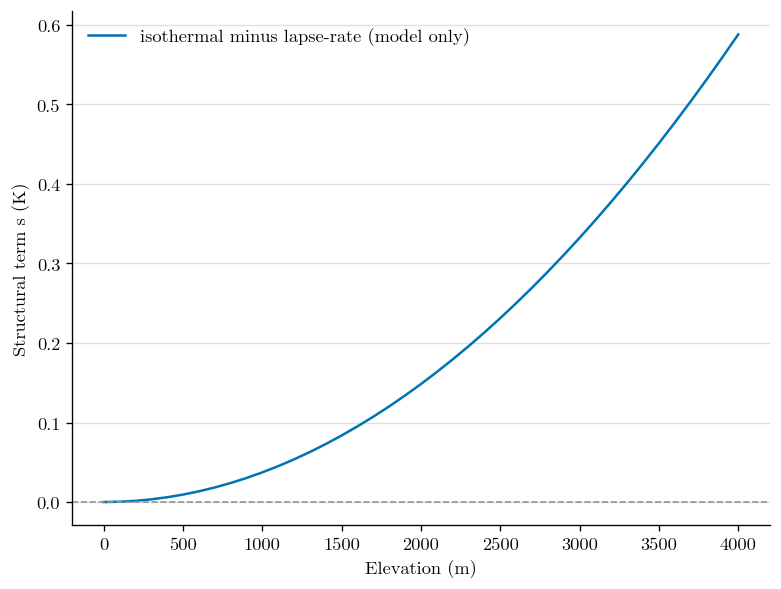

In [13]:
summary = json.loads((RESULTS_DIR / "summary.json").read_text())
ref = json.loads((RESULTS_DIR / "reference_grid.json").read_text())

print(f"Accepted measured sites: {summary['accepted_sites']} (minimum {summary['min_sites_for_test']})")
print(f"Test status: {summary['claim_verdicts']['status']}")
print(f"{'claim':<10}verdict")
for k in ("claim_A", "claim_B", "claim_C"):
    print(f"{k:<10}{summary['claim_verdicts'].get(k, '(not decided)')}")
print()
print("Model-only structural term s = T_b(isothermal) - T_b(lapse), NOT validation:")
print(f"  s(3000 m) = {ref['at_3000_m_K']:.3f} K")
print(f"  s(4000 m) = {ref['at_4000_m_K']:.3f} K")

z = np.array(ref["z_m"])
s = np.array(ref["structural_K"])
fig, ax = plt.subplots()
ax.plot(z, s, color=COLOURS["method"], label="isothermal minus lapse-rate (model only)")
ax.axhline(0, color=COLOURS["baseline"], lw=1, ls="--")
ax.set_xlabel("Elevation (m)")
ax.set_ylabel("Structural term s (K)")
ax.legend()
plt.show()


## Interpreting the results

- **The measurement test is not decided.** With 0 accepted measured sites, below the 15-site minimum, every claim is UNDERPOWERED and untested. The notebook does not conclude how well either barometric formula predicts measured boiling points.
- **The numbers shown are model-only.** The structural term is the difference between the two barometric formulas themselves. It is a property of the formulas and the standard atmosphere, and it reproduces the earlier screen (about 0.33 K at 3000 m and 0.59 K at 4000 m). It does not show that either formula matches nature.
- **What would settle the question.** Measured records with elevation, station pressure, boiling temperature and a stated uncertainty, at 15 or more sites, would allow the claim verdicts to be decided. Candidate sources and the reasons they were dropped are recorded in `data/candidates.csv` in the source artifact.